## RGB to HIS Transformation

In [1]:
import cv2
import numpy as np
import math
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('image.jpg')

In [3]:
bgr = np.float32(img) / 255

In [4]:
b = bgr[:, :, 0]
g = bgr[:, :, 1]
r = bgr[:, :, 2]

In [5]:
I = np.divide(b+g+r, 3)

In [6]:
minimum = np.minimum(np.minimum(r, g), b)
s = 1 - (3 * minimum / (b + g+ r + 0.001))

In [7]:
num = 0.5 * ((r - g) + (r - b))

In [8]:
denom = np.sqrt(np.square(r - g) + ((r - b) * (g - b)))

In [12]:
theta = np.divide(num, denom)


C:\Users\sumee\AppData\Local\Temp\ipykernel_30836\3964855451.py:1: RuntimeWarning: invalid value encountered in divide
  theta = np.divide(num, denom)


In [13]:
for i in range(0, theta.shape[0]):
    for j in range(0, theta.shape[0]):
        theta[i][j] = math.acos(theta[i, j])
        if b[i, j] < g[i, j]:
            theta[i, j] = theta[i, j]
        else:
            theta[i, j] = ((360 * math.pi) / 180.0) - theta[i, j]

In [14]:
img1 = cv2.merge([theta, s, I])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..6.2831855].


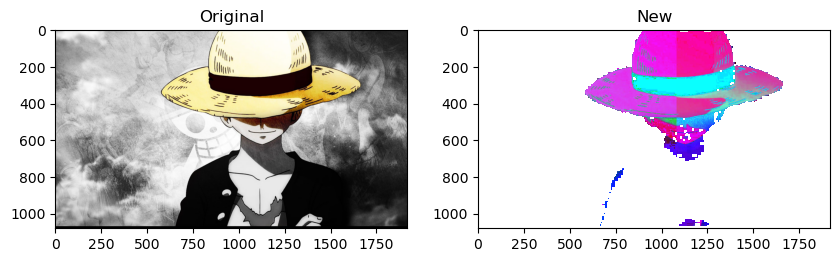

In [16]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Original")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

plt.subplot(1, 2, 2)
plt.title('New')
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))

plt.show()

In [ ]:
``